# NB01 - Praproses Dataset

Notebook ini memfilter kelas buah menggunakan dua rentang HSV yang ditetapkan pada konfigurasi: Red-Orange dan Green-Yellow. Pencocokan dan keputusan dilakukan pada tingkat kelas: piksel dari area tengah semua gambar sekelas dipool, kemudian jumlah piksel yang masuk ke setiap rentang dihitung. Kelas dengan kecocokan terbanyak ditetapkan ke domain tersebut; hasil seri atau tanpa kecocokan tidak diloloskan.

1. Setup dan konfigurasi
2. Inventarisasi dataset mentah
3. Seleksi domain kelas dengan rentang HSV
4. Deduplikasi pHash per kelas
5. Center crop, resize, dan pembuatan manifest
6. Verifikasi hasil praproses
7. Undersampling seimbang per kelas dan domain
8. Analisis ringkas dan ekspor


In [14]:
%pip install opencv-python-headless numpy pillow imagehash pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


## Tahap 1 - Setup dan Konfigurasi

In [15]:
from __future__ import annotations

import json
import random
import sys
import time
from pathlib import Path

import os
import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

CORE_CANDIDATES = [Path.cwd() / "core", *[p / "core" for p in Path.cwd().parents]]
CORE_DIR = next((p for p in CORE_CANDIDATES if (p / "utils.py").exists()), None)
if CORE_DIR is None:
    raise FileNotFoundError("Folder core/utils.py tidak ditemukan")
if str(CORE_DIR) not in sys.path:
    sys.path.insert(0, str(CORE_DIR))
from utils import find_research_root, sha256_file, write_csv, write_json

RESEARCH_ROOT = find_research_root("datasets/raw/fruits")
RAW_DATASET_DIR = RESEARCH_ROOT / "datasets" / "raw" / "fruits"
OUTPUT_DIR = RESEARCH_ROOT / "notebooks" / "01" / "output" / "hsv_domain_ranges"
PROCESSED_DIR = RESEARCH_ROOT / "datasets" / "processed" / "hsv_domain_ranges"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SUBSET = "train"
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
PHASH_THRESHOLD = 4
OUTPUT_SIZE = 512
RANDOM_SEED = 42
METHOD_VERSION = "dataset-preparation-7.0-fixed-hsv-domain-ranges"

# Fixed HSV domain ranges specified for this preparation run.
# OpenCV hue is stored from 0 to 179; the configured Hue intervals use degrees.
HSV_DOMAIN_RANGES = {
    "Red-Orange": {
        "hue": [(0, 15), (300, 359)],
        "saturation": (200, 240),
        "value": (70, 170),
    },
    "Green-Yellow": {
        "hue": [(40, 100)],
        "saturation": (40, 230),
        "value": (70, 200),
    },
}
COLOR_SAMPLES_PER_IMAGE = 1000
CENTER_PRIOR_FRACTION = 0.50

ALL_RAW_CLASSES = sorted(
    directory.name for directory in RAW_DATASET_DIR.iterdir()
    if directory.is_dir() and directory.name != "000neg" and (directory / SUBSET).exists()
)


## Tahap 2 - Inventarisasi Seluruh Kelas Mentah

In [16]:
def list_images(directory: Path) -> list[Path]:
    return sorted(path for path in directory.rglob("*") if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS)

inventory_rows = []
for source_class in ALL_RAW_CLASSES:
    class_dir = RAW_DATASET_DIR / source_class / SUBSET
    paths = list_images(class_dir) if class_dir.exists() else []
    inventory_rows.append({"source_class": source_class, "subset": SUBSET, "raw_image_count": len(paths), "source_directory": str(class_dir)})

inventory = pd.DataFrame(inventory_rows)
if (inventory["raw_image_count"] == 0).any():
    missing = inventory.loc[inventory["raw_image_count"] == 0, "source_class"].tolist()
    raise RuntimeError(f"Kelas tanpa citra pada subset train: {missing}")

print(inventory.to_string(index=False))
print(f"Total kelas mentah: {len(inventory)}")
print(f"Total citra raw: {int(inventory['raw_image_count'].sum())}")


  source_class subset  raw_image_count                                                           source_directory
      001apple  train              418       C:\colorblind_simulation\research\datasets\raw\fruits\001apple\train
     002orange  train              432      C:\colorblind_simulation\research\datasets\raw\fruits\002orange\train
       003pear  train              268        C:\colorblind_simulation\research\datasets\raw\fruits\003pear\train
     004tomato  train              411      C:\colorblind_simulation\research\datasets\raw\fruits\004tomato\train
 005strawberry  train              450  C:\colorblind_simulation\research\datasets\raw\fruits\005strawberry\train
     006banana  train              394      C:\colorblind_simulation\research\datasets\raw\fruits\006banana\train
 007watermelon  train              239  C:\colorblind_simulation\research\datasets\raw\fruits\007watermelon\train
       008kiwi  train              311        C:\colorblind_simulation\research\datasets

## Tahap 3 - Seleksi Kelas dengan Rentang HSV

Seluruh kelas dataset diperiksa menggunakan dua rentang HSV yang dicantumkan pada konfigurasi notebook:

- **Red-Orange:** Hue 0-15 atau 300-359, Saturation 200-240, Value 70-170.
- **Green-Yellow:** Hue 40-100, Saturation 40-230, Value 70-200.

Hue pada citra OpenCV berada pada skala 0-179; kode mengalikannya dengan dua agar sesuai dengan rentang Hue dalam derajat. Saturation dan Value tetap pada skala 0-255. Untuk setiap kelas, kode mempool sampel piksel dari area tengah gambar, menghitung jumlah piksel yang cocok dengan setiap rentang, lalu menetapkan kelas ke domain dengan jumlah kecocokan terbanyak. Jika kedua jumlah seri atau sama-sama nol, kelas diberi status ambigu/tidak cocok. Keputusan dibuat per kelas, bukan per gambar.

Rentang ini merupakan kriteria operasional yang ditetapkan untuk eksperimen ini, bukan persamaan yang diklaim berasal dari sumber literatur tertentu. Rentang luas dapat menerima kombinasi HSV yang beragam; hasil kecocokan dan status setiap kelas disimpan dalam audit untuk diperiksa. Sampling area tengah membantu mengurangi pengaruh latar, tetapi tidak menghilangkannya.


In [17]:
def list_images(directory: Path) -> list[Path]:
    return sorted(
        path for path in directory.rglob("*")
        if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
    )


def collect_class_hsv_samples(image_paths: list[Path]) -> np.ndarray:
    """Pool a fixed number of center-region HSV pixels from each image in a class."""
    hsv_batches: list[np.ndarray] = []
    rng = np.random.default_rng(RANDOM_SEED)

    for image_path in image_paths:
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        if image_bgr is None:
            continue
        height, width = image_bgr.shape[:2]
        roi_h = max(1, int(height * CENTER_PRIOR_FRACTION))
        roi_w = max(1, int(width * CENTER_PRIOR_FRACTION))
        top = (height - roi_h) // 2
        left = (width - roi_w) // 2
        roi = image_bgr[top:top + roi_h, left:left + roi_w]
        pixels = roi.reshape(-1, 3)
        if pixels.size == 0:
            continue
        sample_size = min(COLOR_SAMPLES_PER_IMAGE, len(pixels))
        sampled = pixels[rng.choice(len(pixels), size=sample_size, replace=False)]
        hsv_batches.append(cv2.cvtColor(sampled.reshape(-1, 1, 3), cv2.COLOR_BGR2HSV).reshape(-1, 3))

    if not hsv_batches:
        return np.empty((0, 3), dtype=np.uint8)
    return np.vstack(hsv_batches)


def count_domain_matches(hsv_pixels: np.ndarray, domain_name: str) -> int:
    """Count pixels inside one configured HSV domain range."""
    bounds = HSV_DOMAIN_RANGES[domain_name]
    hue_degrees = hsv_pixels[:, 0].astype(np.int16) * 2
    saturation = hsv_pixels[:, 1].astype(np.int16)
    value = hsv_pixels[:, 2].astype(np.int16)
    hue_match = np.zeros(len(hsv_pixels), dtype=bool)
    for lower, upper in bounds["hue"]:
        hue_match |= (hue_degrees >= lower) & (hue_degrees <= upper)
    saturation_match = (saturation >= bounds["saturation"][0]) & (saturation <= bounds["saturation"][1])
    value_match = (value >= bounds["value"][0]) & (value <= bounds["value"][1])
    return int(np.count_nonzero(hue_match & saturation_match & value_match))


def evaluate_class_hsv(class_name: str, image_paths: list[Path]) -> dict:
    """Compare the pooled class pixels against both configured HSV ranges."""
    hsv_pixels = collect_class_hsv_samples(image_paths)
    result = {
        "source_class": class_name,
        "image_count": len(image_paths),
        "sampled_pixel_count": int(len(hsv_pixels)),
        "matched_domain": "",
        "red_orange_match_count": 0,
        "green_yellow_match_count": 0,
        "matched_pixel_count": 0,
        "matched_pixel_ratio": 0.0,
        "domain": "NoHSVMatch",
        "status": "Rejected",
        "rejection_reason": "no_hsv_match",
    }
    if len(hsv_pixels) == 0:
        result["rejection_reason"] = "no_usable_pixels"
        return result

    match_counts = {
        domain_name: count_domain_matches(hsv_pixels, domain_name)
        for domain_name in HSV_DOMAIN_RANGES
    }
    result["red_orange_match_count"] = match_counts["Red-Orange"]
    result["green_yellow_match_count"] = match_counts["Green-Yellow"]
    result["table_domain_match_counts"] = json.dumps(match_counts, sort_keys=True)
    maximum = max(match_counts.values())
    result["matched_pixel_count"] = int(maximum)
    result["matched_pixel_ratio"] = float(maximum / len(hsv_pixels))
    winners = [name for name, count in match_counts.items() if count == maximum and count > 0]
    if not winners:
        return result
    if len(winners) != 1:
        result["domain"] = "Ambiguous"
        result["status"] = "Ambiguous"
        result["rejection_reason"] = "tie_between_domains"
        return result

    winner = winners[0]
    result["matched_domain"] = winner
    result["domain"] = winner
    result["status"] = "Eligible"
    result["rejection_reason"] = ""
    return result


print("Mencocokkan semua kelas dengan kedua rentang HSV yang dikonfigurasi...")
class_color_records = []
class_image_paths: dict[str, list[Path]] = {}
for class_name in ALL_RAW_CLASSES:
    paths = list_images(RAW_DATASET_DIR / class_name / SUBSET)
    class_image_paths[class_name] = paths
    class_color_records.append(evaluate_class_hsv(class_name, paths))

hue_audit = pd.DataFrame(class_color_records)
selected_audit = hue_audit[hue_audit["status"] == "Eligible"].copy()
red_selected = sorted(selected_audit.loc[selected_audit["domain"] == "Red-Orange", "source_class"].tolist())
green_selected = sorted(selected_audit.loc[selected_audit["domain"] == "Green-Yellow", "source_class"].tolist())
if not red_selected or not green_selected:
    raise RuntimeError(
        "Kedua domain harus memiliki setidaknya satu kelas yang cocok. "
        f"Red-Orange={red_selected}, Green-Yellow={green_selected}. "
        "Periksa laporan audit rentang HSV dan skala warna dataset."
    )

SELECTED_CLASSES = tuple(sorted(red_selected + green_selected))
valid_domain_by_class = {
    **{name: "Red-Orange" for name in red_selected},
    **{name: "Green-Yellow" for name in green_selected},
}
hue_audit.loc[hue_audit["status"] == "Eligible", "status"] = "Selected"
eliminated_classes = hue_audit.loc[hue_audit["status"] != "Selected", "source_class"].tolist()
valid_images_by_class = {
    class_name: class_image_paths[class_name]
    for class_name in SELECTED_CLASSES
}

print("Kelas Red-Orange terpilih:", red_selected)
print("Kelas Green-Yellow terpilih:", green_selected)
print("Rentang HSV yang digunakan:", HSV_DOMAIN_RANGES)
print(hue_audit.sort_values(["status", "source_class"]).to_string(index=False))
print(f"Total citra pada kelas terpilih, sebelum deduplikasi: {sum(map(len, valid_images_by_class.values()))}")


Mencocokkan semua kelas dengan kedua rentang HSV yang dikonfigurasi...
Kelas Red-Orange terpilih: ['001apple', '005strawberry', '010pomegranate', '013grape']
Kelas Green-Yellow terpilih: ['002orange', '003pear', '004tomato', '006banana', '007watermelon', '008kiwi', '009peach', '011pineapple', '012starfruit', '014lemon', '015pomelo', '016mango', '017durian', '018hami', '019papaya']
Rentang HSV yang digunakan: {'Red-Orange': {'hue': [(0, 15), (300, 359)], 'saturation': (200, 240), 'value': (70, 170)}, 'Green-Yellow': {'hue': [(40, 100)], 'saturation': (40, 230), 'value': (70, 200)}}
  source_class  image_count  sampled_pixel_count matched_domain  red_orange_match_count  green_yellow_match_count  matched_pixel_count  matched_pixel_ratio       domain   status rejection_reason                    table_domain_match_counts
      001apple          418               418000     Red-Orange                   15957                      1884                15957             0.038175   Red-Orange Sel

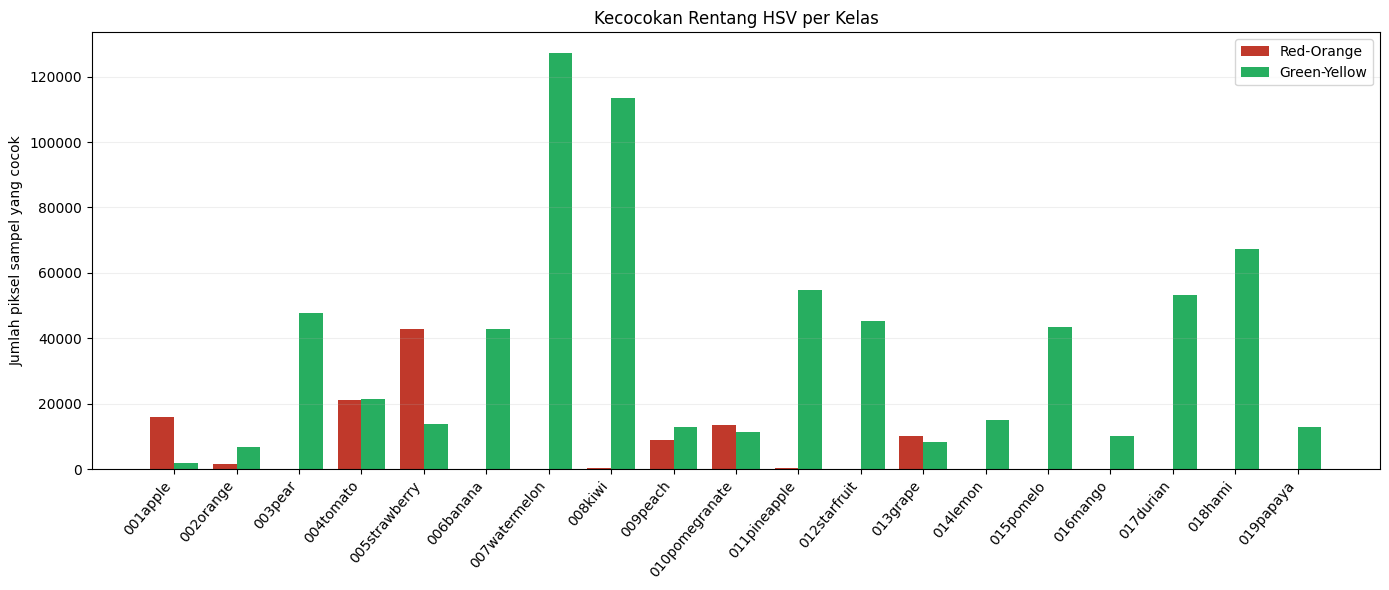

In [18]:
# Jumlah kecocokan terhadap dua rentang HSV pada level kelas
plot_data = hue_audit.sort_values("source_class")
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(plot_data))
width = 0.38
ax.bar(x - width / 2, plot_data["red_orange_match_count"], width, label="Red-Orange", color="#c0392b")
ax.bar(x + width / 2, plot_data["green_yellow_match_count"], width, label="Green-Yellow", color="#27ae60")
ax.set_xticks(x)
ax.set_xticklabels(plot_data["source_class"], rotation=50, ha="right")
ax.set_ylabel("Jumlah piksel sampel yang cocok")
ax.set_title("Kecocokan Rentang HSV per Kelas")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


### Analisis Hasil Seleksi HSV

Grafik memperlihatkan jumlah piksel hasil pooling per kelas yang cocok dengan rentang Red-Orange dan Green-Yellow. Status terpilih mengikuti rentang dengan kecocokan terbanyak; jika hasil seri atau kedua rentang tidak cocok, kelas tidak lolos. Nilai ini dihitung dari piksel sampel pooled, bukan dari keputusan per gambar. Rincian hitungan dan status setiap kelas tersimpan di `class_color_audit.csv`.


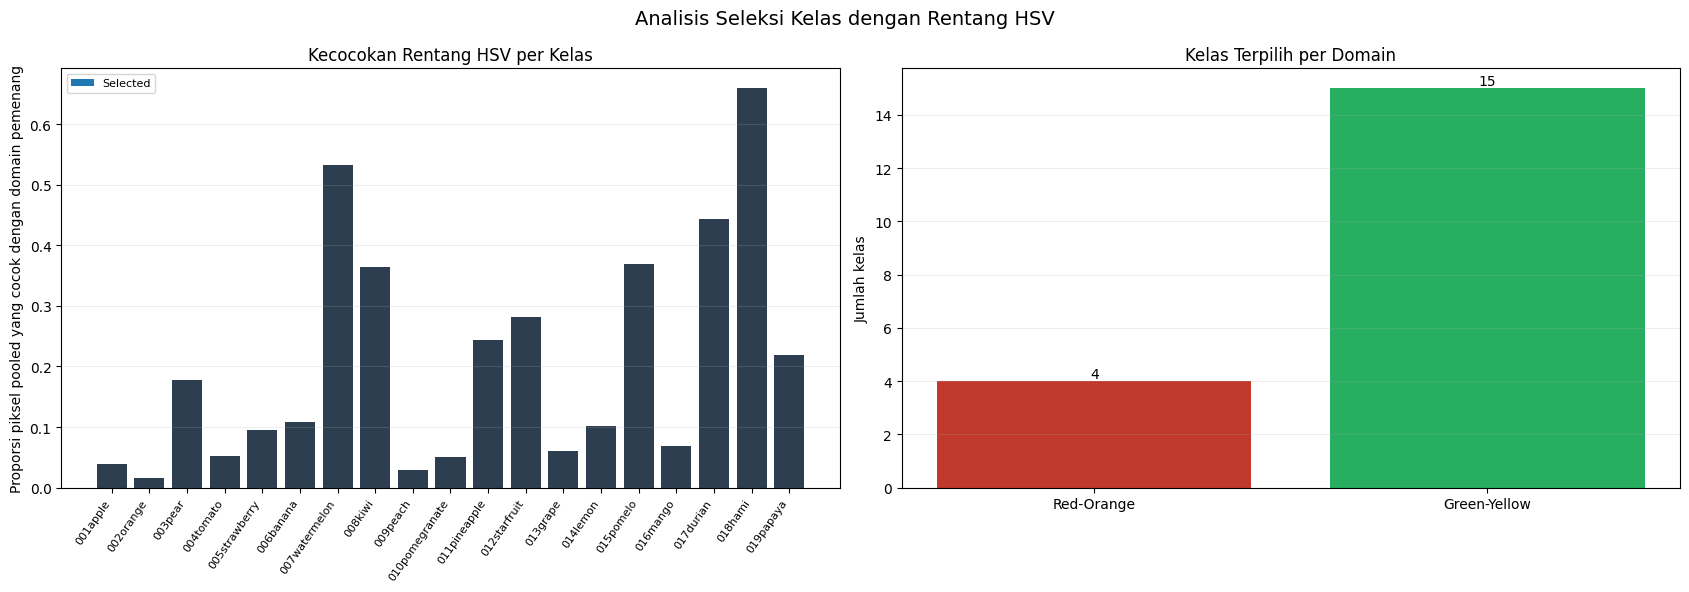

Grafik analisis seleksi kelas disimpan: C:\colorblind_simulation\research\notebooks\01\output\hsv_domain_ranges\class_selection_analysis.png


In [19]:
# Analisis hasil seleksi berbasis dua rentang HSV
plot_data = hue_audit.sort_values(["status", "source_class"]).reset_index(drop=True)
status_colors = {
    "Selected": "#2c3e50",
    "Rejected": "#bdc3c7",
    "Ambiguous": "#8e44ad",
}
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
x = np.arange(len(plot_data))
colors = plot_data["status"].map(status_colors).fillna("#bdc3c7")
axes[0].bar(x, plot_data["matched_pixel_ratio"].fillna(0), color=colors)
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_data["source_class"], rotation=55, ha="right", fontsize=8)
axes[0].set_ylabel("Proporsi piksel pooled yang cocok dengan domain pemenang")
axes[0].set_title("Kecocokan Rentang HSV per Kelas")
axes[0].grid(axis="y", alpha=0.2)
for status, color in status_colors.items():
    if status in set(plot_data["status"]):
        axes[0].bar([], [], color=color, label=status)
axes[0].legend(fontsize=8)

selected_counts = (
    plot_data[plot_data["status"] == "Selected"]
    .groupby("domain")["source_class"].nunique()
    .reindex(["Red-Orange", "Green-Yellow"], fill_value=0)
)
axes[1].bar(selected_counts.index, selected_counts.values, color=["#c0392b", "#27ae60"])
axes[1].set_ylabel("Jumlah kelas")
axes[1].set_title("Kelas Terpilih per Domain")
axes[1].grid(axis="y", alpha=0.2)
for index, value in enumerate(selected_counts.values):
    axes[1].text(index, value, str(int(value)), ha="center", va="bottom")
fig.suptitle("Analisis Seleksi Kelas dengan Rentang HSV", fontsize=14)
fig.tight_layout()
analysis_chart_path = OUTPUT_DIR / "class_selection_analysis.png"
fig.savefig(analysis_chart_path, dpi=180, bbox_inches="tight")
plt.show()
print(f"Grafik analisis seleksi kelas disimpan: {analysis_chart_path}")


## Tahap 4 - Deduplikasi Perceptual Hash (pHash) Intra-Kelas

Deduplikasi dilakukan dalam kelas yang sama menggunakan *perceptual hash* berbasis Discrete Cosine Transform (DCT-II 2D $32 \times 32$) dan kuantisasi median koefisien frekuensi rendah $8 \times 8$ (*Mahmud, Nusrat, & Pan, 2026, Eq. 3-6; Zauner, 2010*).

Dua citra dalam kelas yang sama diklasifikasikan sebagai duplikat visual jika jarak Hamming antar-hash biner 64-bit tidak melebihi ambang batas 4 ($d_H \le 4$).

In [20]:
# -- Deduplikasi Perceptual Hash (pHash) Intra-Kelas --
# Referensi Ilmiah Terverifikasi:
#   Mahmud, M. F., Nusrat, Z., & Pan, W. D. (2026). Electronics, 15(7), 1493.
#   Equations (3)-(6): 2D DCT-II, Median 8x8 Quantization, and Hamming Distance.

def compute_phash(image_path: Path) -> imagehash.ImageHash:
    with Image.open(image_path) as img:
        return imagehash.phash(img)


def deduplicate_images(
    image_paths: list[Path],
    threshold: int = PHASH_THRESHOLD,
) -> tuple[list[Path], list[tuple[Path, Path, int]]]:
    kept: list[Path] = []
    kept_hashes: list[imagehash.ImageHash] = []
    duplicates: list[tuple[Path, Path, int]] = []

    for path in image_paths:
        img_hash = compute_phash(path)
        is_duplicate = False
        for existing_hash, existing_path in zip(kept_hashes, kept):
            distance = img_hash - existing_hash
            if distance <= threshold:
                duplicates.append((path, existing_path, distance))
                is_duplicate = True
                break
        if not is_duplicate:
            kept.append(path)
            kept_hashes.append(img_hash)
    return kept, duplicates


dedup_results: dict[str, list[Path]] = {}
duplicate_records: list[dict] = []

# Hanya memproses citra dari kelas yang cocok dengan kategori sasaran Tabel 2
for cls_name in SELECTED_CLASSES:
    class_images = valid_images_by_class[cls_name]
    kept, dups = deduplicate_images(class_images, threshold=PHASH_THRESHOLD)
    dedup_results[cls_name] = kept
    for dup_path, orig_path, dist in dups:
        duplicate_records.append({
            "class": cls_name,
            "duplicate_file": dup_path.name,
            "kept_file": orig_path.name,
            "hamming_distance": dist,
        })

dedup_df = pd.DataFrame(duplicate_records)
print(f"Total kelas terpilih      : {len(SELECTED_CLASSES)}")
print(f"Total citra murni terpilih : {sum(len(v) for v in valid_images_by_class.values())}")
print(f"Total duplikat disaring   : {len(duplicate_records)}")
print(f"Total citra unik dipertahankan : {sum(len(v) for v in dedup_results.values())}")

# Bentuk daftar kandidat untuk praproses
candidates = [(cls_name, path) for cls_name in SELECTED_CLASSES for path in dedup_results[cls_name]]
print(f"Total kandidat unik siap praproses: {len(candidates)}")


Total kelas terpilih      : 19
Total citra murni terpilih : 4870
Total duplikat disaring   : 178
Total citra unik dipertahankan : 4692
Total kandidat unik siap praproses: 4692


## Tahap 5 - Normalisasi Geometris (Center Crop & Resize)

Citra dipotong secara simetris di bagian tengah (titik potong $(W - W_c)/2$ dan $(H - H_c)/2$) untuk menjaga rasio aspek objek 1:1 tanpa distorsi, kemudian di-resize ke resolusi seragam $512 \times 512$ piksel menggunakan interpolasi area (*Xiao et al., 2025, Eq. 4*).

In [21]:
# -- Normalisasi Geometris: Center-Crop Resizing 512x512 --
# Referensi Ilmiah Terverifikasi:
#   Xiao, Y. et al. (2025). J. Mar. Sci. Eng., 13(5), 936. (Equation 4: Center-Crop Transformation Matrix)

def center_crop_resize(source_path: Path, destination_path: Path, size: int) -> None:
    image = cv2.imread(str(source_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("Citra tidak dapat dibaca oleh OpenCV")
    height, width = image.shape[:2]
    edge = min(height, width)
    top, left = (height - edge) // 2, (width - edge) // 2
    cropped = image[top:top + edge, left:left + edge]
    resized = cv2.resize(cropped, (size, size), interpolation=cv2.INTER_AREA)
    destination_path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(destination_path), resized):
        raise IOError("Citra hasil tidak dapat ditulis")

manifest_rows: list[dict] = []
error_rows: list[dict] = []
for source_class, source_path in candidates:
    output_path = PROCESSED_DIR / source_class / f"{source_path.stem}.png"
    try:
        started = time.perf_counter()
        center_crop_resize(source_path, output_path, OUTPUT_SIZE)
        manifest_rows.append({"subset": SUBSET, "source_class": source_class, "source_file_name": source_path.name, "source_path": str(source_path), "output_file_name": output_path.name, "output_path": str(output_path), "output_sha256": sha256_file(output_path), "processing_seconds": round(time.perf_counter() - started, 6), "method_version": METHOD_VERSION})
    except Exception as error:
        error_rows.append({"stage": "preprocessing", "source_class": source_class, "source_path": str(source_path), "error": str(error)})

manifest = pd.DataFrame(manifest_rows).sort_values(["source_class", "source_file_name"]).reset_index(drop=True)
manifest["color_domain"] = manifest["source_class"].map(valid_domain_by_class)
if manifest.empty:
    raise RuntimeError("Tidak ada citra yang berhasil diproses.")
print(f"Citra berhasil diproses: {len(manifest)}")


KeyboardInterrupt: 

## Tahap 6 - Verifikasi Hasil Praproses

In [ ]:
verification_rows = []
for _, row in manifest.iterrows():
    image = cv2.imread(row["output_path"], cv2.IMREAD_COLOR)
    verification_rows.append({"source_class": row["source_class"], "output_path": row["output_path"], "readable": image is not None, "width": None if image is None else int(image.shape[1]), "height": None if image is None else int(image.shape[0])})
verification = pd.DataFrame(verification_rows)
if not verification["readable"].all() or not ((verification["width"] == OUTPUT_SIZE) & (verification["height"] == OUTPUT_SIZE)).all():
    raise RuntimeError("Verifikasi ukuran atau keterbacaan citra gagal.")
print(f"Seluruh {len(verification)} citra berukuran {OUTPUT_SIZE} × {OUTPUT_SIZE} piksel.")

In [ ]:
import math

# Mengambil 1 sampel acak untuk setiap kelas dari dataframe manifest
if "manifest" not in globals():
    raise RuntimeError(
        "Variabel `manifest` belum tersedia. Jalankan sel Tahap 4 terlebih dahulu."
    )

sample_df = (
    manifest.groupby("source_class")
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

# Hitung jumlah baris & kolom secara dinamis
num_samples = len(sample_df)
ncols = 6
nrows = math.ceil(num_samples / ncols)

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(3 * ncols, 3 * nrows))
axes = axes.flatten()

for idx, row in sample_df.iterrows():
    img = cv2.imread(row['output_path'])
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(img_rgb)
    axes[idx].set_title(row['source_class'], fontsize=12)
    axes[idx].axis('off')

# Matikan sisa subplot kosong jika total slot melebihi jumlah data
for j in range(num_samples, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Tahap 7 - Undersampling Seimbang per Kelas dan Domain

Setelah deduplikasi, setiap kelas terpilih mengambil jumlah citra yang sama, berdasarkan kelas dengan citra valid paling sedikit. Karena jumlah kelas Red-Orange dan Green-Yellow dapat berbeda setelah penerapan cakupan rentang HSV konfigurasi, kode kemudian mengambil jumlah citra yang sama dari kedua domain. Kuota ini adalah keputusan desain sampling untuk perbandingan dataset, bukan persamaan yang diklaim berasal dari artikel. Distribusi kelas dan domain sebelum serta sesudah sampling diekspor agar dapat diaudit.


In [ ]:
# Sampling deterministik: kuota sama per kelas, lalu seimbangkan jumlah total kedua domain.
class_counts_before = manifest.groupby("source_class").size()
domain_counts_before = manifest.groupby("color_domain").size()
class_quota = int(class_counts_before.loc[list(SELECTED_CLASSES)].min())
if class_quota <= 0:
    raise RuntimeError("Kuota undersampling per kelas harus lebih dari nol.")

class_chunks = []
for class_name in SELECTED_CLASSES:
    class_rows = manifest[manifest["source_class"] == class_name]
    class_chunks.append(class_rows.sample(n=class_quota, random_state=RANDOM_SEED))
class_balanced = pd.concat(class_chunks, ignore_index=True)
class_counts_after = class_balanced.groupby("source_class").size()
domain_counts_class_balanced = class_balanced.groupby("color_domain").size()
domain_quota = int(domain_counts_class_balanced.min())
if domain_quota <= 0:
    raise RuntimeError("Kuota undersampling domain harus lebih dari nol.")

# If the domains contain different numbers of classes, sample evenly across classes
# within the larger domain while retaining all selected classes where feasible.
domain_chunks = []
for domain_name in ["Red-Orange", "Green-Yellow"]:
    domain_rows = class_balanced[class_balanced["color_domain"] == domain_name]
    class_names = sorted(domain_rows["source_class"].unique())
    base_quota, remainder = divmod(domain_quota, len(class_names))
    if base_quota == 0:
        raise RuntimeError(
            f"Domain {domain_name} memiliki {len(class_names)} kelas tetapi kuota seimbang "
            f"{domain_quota}; tidak mungkin mempertahankan semua kelas dan menyamakan domain."
        )
    for index, class_name in enumerate(class_names):
        requested = base_quota + (1 if index < remainder else 0)
        class_rows = domain_rows[domain_rows["source_class"] == class_name]
        if requested > len(class_rows):
            raise RuntimeError(f"Kuota {requested} melebihi data kelas {class_name}.")
        domain_chunks.append(class_rows.sample(n=requested, random_state=RANDOM_SEED))

manifest_balanced = (
    pd.concat(domain_chunks, ignore_index=True)
    .sort_values(["color_domain", "source_class", "source_file_name"])
    .reset_index(drop=True)
)
class_counts_after_domain_balance = manifest_balanced.groupby("source_class").size()
domain_counts_after = manifest_balanced.groupby("color_domain").size()
if set(domain_counts_after.index) != {"Red-Orange", "Green-Yellow"} or domain_counts_after.nunique() != 1:
    raise RuntimeError(f"Jumlah domain tidak seimbang: {domain_counts_after.to_dict()}")

print(f"Kuota awal per kelas setelah deduplikasi: {class_quota}")
print(f"Kuota total per domain setelah penyeimbangan: {domain_quota}")
print("Distribusi kelas setelah undersampling:")
print(class_counts_after_domain_balance.to_string())
print("Distribusi domain setelah undersampling:")
print(domain_counts_after.to_string())
print(f"Total citra setelah undersampling: {len(manifest_balanced)}")

manifest_original = manifest.copy()
manifest = manifest_balanced


In [ ]:
# -- Visualisasi Perbandingan Sebelum vs Sesudah Undersampling Domain --
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel kiri: per-kelas buah
cls_names = sorted(list(SELECTED_CLASSES))
before_vals = [int(class_counts_before.get(c, 0)) for c in cls_names]
after_vals = [int(class_counts_after_domain_balance.get(c, 0)) for c in cls_names]
x = np.arange(len(cls_names))
width = 0.38

axes[0].bar(x - width/2, before_vals, width, label="Sebelum Undersampling", color="#4C78A8", edgecolor="black", linewidth=0.4)
axes[0].bar(x + width/2, after_vals, width, label="Sesudah Undersampling", color="#F58518", edgecolor="black", linewidth=0.4)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cls_names, rotation=45, ha="right", fontsize=9)
axes[0].set_ylabel("Jumlah Citra", fontweight="bold")
axes[0].set_title("Distribusi Citra per Kelas Buah", fontweight="bold", pad=10)
axes[0].legend(frameon=True, facecolor="white")

# Panel kanan: per domain warna
domain_names = ["Red-Orange", "Green-Yellow"]
domain_before_vals = [int(domain_counts_before["Red-Orange"]), int(domain_counts_before["Green-Yellow"])]
domain_after_vals = [int(domain_counts_after["Red-Orange"]), int(domain_counts_after["Green-Yellow"])]
xd = np.arange(len(domain_names))

axes[1].bar(xd - width/2, domain_before_vals, width, label="Sebelum (Asimetris)", color=["#e74c3c", "#2ecc71"], alpha=0.5, edgecolor="black")
axes[1].bar(xd + width/2, domain_after_vals, width, label="Sesudah (Seimbang 1:1)", color=["#c0392b", "#27ae60"], edgecolor="black")
axes[1].set_xticks(xd)
axes[1].set_xticklabels(domain_names, fontsize=11, fontweight="bold")
axes[1].set_ylabel("Jumlah Citra", fontweight="bold")
axes[1].set_title(f"Distribusi Domain Warna Seimbang ({domain_quota} per domain)", fontweight="bold", pad=10)
axes[1].legend(frameon=True, facecolor="white")

for i, val in enumerate(domain_after_vals):
    axes[1].text(i + width/2, val + max(1, domain_quota * 0.02), f"{val} citra", ha="center", fontweight="bold")

plt.suptitle(
    f"Tahap 7: Undersampling per Kelas dan Domain (Total: {len(manifest)} Citra)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "undersampling_chart.png", dpi=180, bbox_inches="tight")
plt.show()

# Simpan laporan undersampling
undersample_report = pd.DataFrame({
    "source_class": cls_names,
    "domain": [valid_domain_by_class[c] for c in cls_names],
    "before_count": before_vals,
    "after_count": after_vals,
    "removed": [b - a for b, a in zip(before_vals, after_vals)],
    "initial_class_quota": [class_quota] * len(cls_names),
    "final_count": after_vals,
})
write_csv(undersample_report, OUTPUT_DIR / "undersampling_report.csv", ["source_class"])
print(f"Laporan undersampling disimpan: {OUTPUT_DIR / 'undersampling_report.csv'}")


## Tahap 8 - Analisis Ringkas dan Ekspor

In [ ]:
# -- Tahap 8: Ekspor Seluruh Laporan dan Manifest Praproses --
import shutil

class_counts = manifest.groupby("source_class").size().rename("processed_count")
domain_counts = manifest.groupby("color_domain").size().rename("domain_count")

# 1. Simpan Manifest Utama untuk NB02 (dataset_preparation_report.csv & manifest.csv)
report_path = OUTPUT_DIR / "dataset_preparation_report.csv"
write_csv(manifest, report_path, ["source_class", "source_file_name"])
manifest_csv_path = OUTPUT_DIR / "manifest.csv"
manifest.to_csv(manifest_csv_path, index=False)
print(f"[1/6] Manifest utama NB02 disimpan: {report_path}")

# 2. Simpan Laporan Error Praproses (dataset_preparation_errors.csv & dataset_preparation_error.csv)
error_cols = ["stage", "source_class", "source_path", "error"]
errors_df = pd.DataFrame(error_rows, columns=error_cols) if error_rows else pd.DataFrame(columns=error_cols)
write_csv(errors_df, OUTPUT_DIR / "dataset_preparation_errors.csv", ["stage", "source_class", "source_path"], allow_empty=True)
errors_df.to_csv(OUTPUT_DIR / "dataset_preparation_error.csv", index=False)
print(f"[2/6] Laporan error praproses disimpan: {OUTPUT_DIR / 'dataset_preparation_errors.csv'}")

# 3. Simpan Laporan Verifikasi Ukuran & Keterbacaan (dataset_preparation_verification.csv)
write_csv(verification, OUTPUT_DIR / "dataset_preparation_verification.csv", ["source_class", "output_path"])
print(f"[3/6] Laporan verifikasi citra disimpan: {OUTPUT_DIR / 'dataset_preparation_verification.csv'}")

# 4. Simpan audit seleksi otomatis pada tingkat kelas
class_audit_export = hue_audit.astype(object).where(pd.notna(hue_audit), "")
write_csv(class_audit_export, OUTPUT_DIR / "class_color_audit.csv", ["source_class"])

# 5. Simpan Laporan Deduplikasi pHash (deduplication_report.csv)
dedup_cols = ["class", "duplicate_file", "kept_file", "hamming_distance"]
dedup_export_df = pd.DataFrame(duplicate_records, columns=dedup_cols) if duplicate_records else pd.DataFrame(columns=dedup_cols)
write_csv(dedup_export_df, OUTPUT_DIR / "deduplication_report.csv", ["class", "duplicate_file"], allow_empty=True)
print(f"[4/6] Laporan deduplikasi pHash disimpan: {OUTPUT_DIR / 'deduplication_report.csv'}")

# 6. Simpan Salinan Grafik Ringkasan (dataset_preparation_summary.png)
if (OUTPUT_DIR / "undersampling_chart.png").exists():
    shutil.copy2(OUTPUT_DIR / "undersampling_chart.png", OUTPUT_DIR / "dataset_preparation_summary.png")
    print(f"[5/6] Grafik ringkasan visual disimpan: {OUTPUT_DIR / 'dataset_preparation_summary.png'}")

# 7. Ekspor Metadata Terstruktur JSON (dataset_preparation_summary.json)
summary = {
    "method_version": METHOD_VERSION,
    "selection_method": "class-level pooled HSV matching against configured Red-Orange and Green-Yellow ranges",
    "domain_hsv_ranges": HSV_DOMAIN_RANGES,
    "match_policy": "per class, maximum pooled pixel matches across both configured domain ranges; ties and zero matches are not selected",
    "algorithm_parameters": {
        "color_samples_per_image_for_class_pool": COLOR_SAMPLES_PER_IMAGE,
        "center_prior_fraction": CENTER_PRIOR_FRACTION,
        "class_quota_after_deduplication": class_quota,
        "balanced_domain_quota": domain_quota,
    },
    "subset": SUBSET,
    "total_raw_classes": len(ALL_RAW_CLASSES),
    "selected_classes": list(SELECTED_CLASSES),
    "eliminated_classes": eliminated_classes,
    "red_orange_classes": red_selected,
    "green_yellow_classes": green_selected,
    "raw_image_count": int(inventory["raw_image_count"].sum()),
    "selected_class_image_count_before_deduplication": sum(len(v) for v in valid_images_by_class.values()),
    "post_dedup_count": len(manifest_original),
    "final_processed_count": len(manifest),
    "red_orange_count": int(domain_counts["Red-Orange"]),
    "green_yellow_count": int(domain_counts["Green-Yellow"]),
    "duplicates_removed": len(duplicate_records),
    "preprocessing_errors": len(error_rows),
    "output_size": OUTPUT_SIZE,
    "phash_threshold": PHASH_THRESHOLD,
    "random_seed": RANDOM_SEED,
    "generated_files": [
        "class_color_audit.csv",
        "class_selection_analysis.png",
        "dataset_preparation_report.csv",
        "dataset_preparation_errors.csv",
        "dataset_preparation_error.csv",
        "dataset_preparation_verification.csv",
        "deduplication_report.csv",
        "undersampling_report.csv",
        "undersampling_chart.png",
        "dataset_preparation_summary.png",
        "dataset_preparation_summary.json",
    ],
}

output_json_path = OUTPUT_DIR / "dataset_preparation_summary.json"
with open(output_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print(f"[6/6] Ringkasan JSON diekspor ke: {output_json_path}")
